# From TESS pixels to the rotation light curve of (10088) Digne

Digne crossed camera 3, CCD 4 during TESS sector 72. We measure its brightness from full-frame images and fold the measurements at a previously determined rotation period. The two unequal minima make this a useful example of an asymmetric light curve.

Run the cells in order. The first run downloads roughly 2.4 GB of pixel data. Later runs can use the local pixel cache.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import binned_statistic

from tess_sso.asteroid import Asteroid
from tess_sso.settings import Settings

visit = (72, 3, 4)  # sector, camera, CCD
digne = Asteroid("10088", settings=Settings(group_minutes=30))

## Download the strip along the track

The download plan follows the predicted position of Digne across the detector. It includes the pixels needed to measure both the asteroid and its local background.

In [2]:
plan = digne.plan(*visit)
print(plan.describe())
download = digne.download(*visit)
print(f"{download.downloaded:,} new pixels, {download.already_stored:,} already on disk")

s0072-3-4: all 29789 pixel(s) are stored; nothing to download


0 new pixels, 29,789 already on disk


## Model the sky and measure Digne

Build the source masks, fit scattered light on usable background pixels and fit the field stars with the TESS pixel response function (PRF). The asteroid photometry then fits a moving PRF to the exposures in each 30-minute group.

In [3]:
masks = digne.masks(*visit)
background = digne.scattered_light(*visit, masks=masks)
stars = digne.stellar_model(*visit, masks=masks, scattered=background)
print(masks.describe())

tess_sso/.venv/lib/python3.12/site-packages/lkprf/tessprf.py:62: LKPRFWarning: `targets` contains collateral pixels: Row(s) > 2048)
  warnings.warn(


tess_sso/masks.py:97: RuntimeWarning: divide by zero encountered in divide
  ratio = np.sort(star_image[candidates] / noise_image[candidates])


grid (862, 132) at (1202, 353), 4 segment(s)
  segment 0: usable 84.9% of 29789 strip px, k = 10; stars Gaia 4057, data 3627, Gaia only 864, data only (missing from Gaia) 434; asteroid 0
  segment 1: usable 81.9% of 29789 strip px, k = 10; stars Gaia 4276, data 4126, Gaia only 797, data only (missing from Gaia) 647; asteroid 645
  segment 2: usable 79.9% of 29789 strip px, k = 10; stars Gaia 4126, data 3868, Gaia only 756, data only (missing from Gaia) 498; asteroid 1575
  segment 3: usable 78.8% of 29789 strip px, k = 10; stars Gaia 4440, data 4596, Gaia only 750, data only (missing from Gaia) 906; asteroid 1241


In [4]:
phot = digne.photometry(*visit, masks=masks, scattered=background, stellar=stars)
with digne.lightcurve(*visit, masks=masks, photometry=phot) as product:
    lc = product["LIGHTCURVE_PRF"].data.copy()
    geometry = product["EXTRAS"].data.copy()
print(f"{len(lc):,} groups written to {digne.lightcurve_path(*visit).name}")

tess_sso/.venv/lib/python3.12/site-packages/lkprf/tessprf.py:62: LKPRFWarning: `targets` contains collateral pixels: Row(s) > 2048)
  warnings.warn(


709 groups written to tess-10088-s0072-3-4-lc.fits


## Inspect the measured flux

Use finite measurements with positive flux and random uncertainty. For this example we keep only groups with both spacecraft and asteroid quality flags clear. The grey points show the measurements omitted by these cuts.

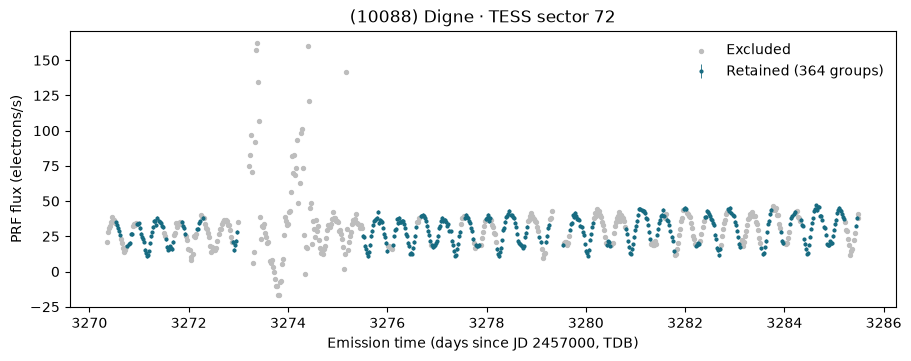

In [5]:
time = lc["TIME_EMIT"]  # emission time, days relative to JD 2457000 (TDB)
flux = lc["FLUX"]       # electrons per second
err = lc["FLUX_ERR"]
keep = (np.isfinite(time) & np.isfinite(flux) & np.isfinite(err)
        & (flux > 0) & (err > 0) & (lc["QUALITY"] == 0) & (lc["SSO_QUALITY"] == 0))

fig, ax = plt.subplots(figsize=(9, 3.5), layout="constrained")
ax.scatter(time[~keep], flux[~keep], s=8, color="0.74", label="Excluded")
ax.errorbar(time[keep], flux[keep], yerr=err[keep], fmt=".", ms=4, lw=0.6,
            color="#176b81", label=f"Retained ({keep.sum()} groups)")
ax.set(xlabel="Emission time (days since JD 2457000, TDB)", ylabel="PRF flux (electrons/s)",
       title="(10088) Digne · TESS sector 72")
ax.legend(frameon=False)
plt.show()

## Fold at the adopted period

Use the synodic period of **21.2659 hours** adopted in the earlier sector 72 analysis of Digne (`asteroid_10088.ipynb`). Phase zero uses its reference emission time, 3270.60795 days after JD 2457000.

To reduce the slow change in brightness from viewing distance, multiply flux by the square of each distance, Sun–asteroid and TESS–asteroid, then divide by the median corrected flux. Each orange point is the median in one of 40 equal phase bins. The individual measurements show the scatter around the two minima.

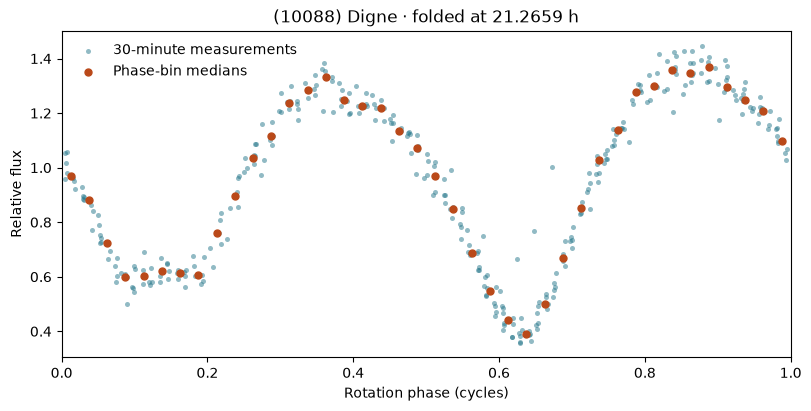

In [6]:
period_hours = 21.2659
epoch = 3270.60795
phase = ((time[keep] - epoch) / (period_hours / 24)) % 1

r = geometry["SUN_DISTANCE"][keep]    # astronomical units
delta = geometry["OBS_DISTANCE"][keep]
corrected = flux[keep] * (r * delta)**2
relative_flux = corrected / np.median(corrected)

medians, edges, _ = binned_statistic(phase, relative_flux, statistic="median",
                                     bins=40, range=(0, 1))
centres = (edges[1:] + edges[:-1]) / 2

fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
ax.scatter(phase, relative_flux, s=13, color="#24768a", alpha=0.5, linewidths=0,
           label="30-minute measurements")
ax.scatter(centres, medians, s=25, color="#ba4919", label="Phase-bin medians")
ax.set(xlim=(0, 1), xlabel="Rotation phase (cycles)", ylabel="Relative flux",
       title=f"(10088) Digne · folded at {period_hours:.4f} h")
ax.legend(frameon=False)
plt.show()